# HealthPulse AI 360 — J7 : Corrélations, analyse multivariée et visualisations interactives

## Question de recherche
Existe-t-il une association statistique entre
le vieillissement démographique et la prévalence
de prise en charge pour un diabète ?

## Méthodologie
1. Contrôler les données.
2. Calculer Pearson et Spearman.
3. Créer un scatter plot interactif.
4. Construire une heatmap des corrélations.
5. Étudier l'influence des valeurs atypiques.
6. Documenter les résultats et leurs limites.

## 1. Importer les librairies

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"

In [2]:
import pandas as pd
import numpy as np
import plotly.express as px

from pathlib import Path

## 2. Définir les chemins

In [3]:
RACINE = Path(r"D:\Projets_Data\HealthPulse_AI_360")

PROCESSED = RACINE / "data" / "processed"
FIGURES = RACINE / "outputs" / "figures"
TABLES = RACINE / "outputs" / "tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

In [4]:
fichier = (
    PROCESSED
    / "healthpulse_diabete_demographie_2024_j05.csv"
)

assert fichier.exists(), "Fichier J5 introuvable"

df_j7 = pd.read_csv(
    fichier,
    dtype={
        "code_dept": "string",
        "region": "string"
    }
)

display(df_j7.head())
print("Dimensions :", df_j7.shape)

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,code_dept,ntop,...,libelle_sexe,tri,effectif_num,code_region_insee,nom_departement,population_totale,population_60_plus,part_60_plus_pct,part_75_plus_pct,part_femmes_pct
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,4,974,89860.0,...,tous sexes,2.0,89860.0,4,La Réunion,897613.0,193653.0,21.574220,5.958247,52.388502
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,6,976,7770.0,...,tous sexes,2.0,7770.0,6,Mayotte,320646.0,13843.0,4.317222,0.915028,52.338092
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,77,93930.0,...,tous sexes,2.0,93930.0,11,Seine-et-Marne,1479706.0,317898.0,21.483862,7.238870,51.245383
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,78,78590.0,...,tous sexes,2.0,78590.0,11,Yvelines,1495123.0,343647.0,22.984530,8.703766,51.288891
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,91,80230.0,...,tous sexes,2.0,80230.0,11,Essonne,1347483.0,289728.0,21.501422,7.842696,50.876560


Dimensions : (101, 24)


## 3. Vérifier la qualité des indicateurs

In [5]:
#Vérifier l'unicité départementale

print("Départements :", df_j7["code_dept"].nunique())

print(
    "Doublons :",
    df_j7["code_dept"].duplicated().sum()
)

assert df_j7["code_dept"].notna().all()
assert df_j7["code_dept"].is_unique

Départements : 101
Doublons : 0


In [6]:
#Vérifier l'année

print(df_j7["annee"].unique())

[2024]


In [7]:
#Préparer les variables numériques

variables = [
    "prev",
    "part_60_plus_pct",
    "part_75_plus_pct",
    "part_femmes_pct",
    "population_totale"
]

for col in variables:
    df_j7[col] = pd.to_numeric(
        df_j7[col]
        .astype("string")
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

In [8]:
#Vérifier les pourcentages

pourcentages = [
    "prev",
    "part_60_plus_pct",
    "part_75_plus_pct",
    "part_femmes_pct"
]

for col in pourcentages:
    valeurs = df_j7[col].dropna()
    assert valeurs.between(0, 100).all()

In [9]:
#Repérer Mayotte et La Guyane

codes_atypiques = ["973", "976"]

df_atypiques = df_j7[
    df_j7["code_dept"].isin(codes_atypiques)
]

display(
    df_atypiques[
        [
            "code_dept",
            "nom_departement",
            "part_60_plus_pct",
            "part_75_plus_pct",
            "prev"
        ]
    ]
)

,code_dept,nom_departement,part_60_plus_pct,part_75_plus_pct,prev
1,976,Mayotte,4.317222,0.915028,6.094
30,973,Guyane,11.000132,2.50379,6.601


## 4. Comprendre les corrélations

In [10]:
#Construire le DataFrame d'analyse

df_analyse = df_j7.dropna(
    subset=[
        "part_60_plus_pct",
        "prev"
    ]
).copy()

print("Départements utilisables :", len(df_analyse))

Départements utilisables : 101


In [11]:
#Calculer la corrélation de Pearson

pearson = df_analyse[
    "part_60_plus_pct"
].corr(
    df_analyse["prev"],
    method="pearson"
)

print("Pearson :", round(pearson, 3))

Pearson : 0.316


In [12]:
#Calculer Spearman

spearman = df_analyse[
    "part_60_plus_pct"
].corr(
    df_analyse["prev"],
    method="spearman"
)

print("Spearman :", round(spearman, 3))

Spearman : 0.341


## 5. Plotly interactif

In [15]:
#Préparer la variable Région

df_analyse["region"] = (
    df_analyse["region"]
    .astype("string")
    .fillna("Non renseignée")
)

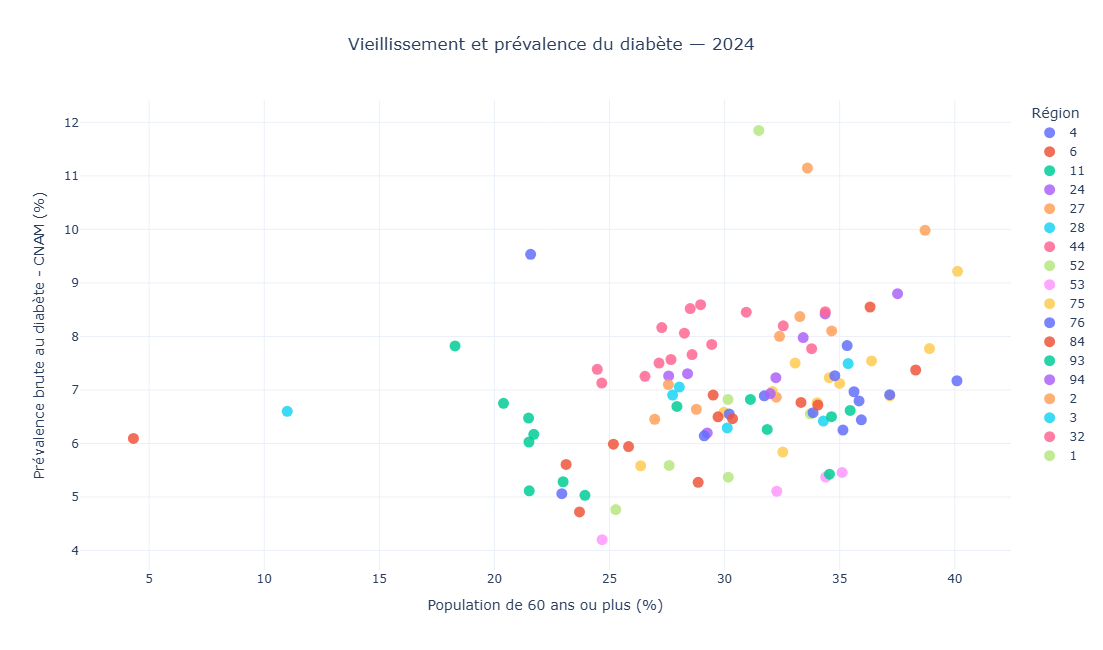

In [17]:
#Créer le graphique

fig_scatter = px.scatter(
    df_analyse,
    x="part_60_plus_pct",
    y="prev",
    color="region",
    hover_name="nom_departement",
    hover_data={
        "code_dept": True,
        "part_60_plus_pct": ":.1f",
        "prev": ":.2f"
    },
    title="Vieillissement et prévalence du diabète — 2024",
    labels={
        "part_60_plus_pct": "Population de 60 ans ou plus (%)",
        "prev": "Prévalence brute au diabète - CNAM (%)",
        "region": "Région"
    },
    template="plotly_white",
    opacity=0.85
)

fig_scatter.update_traces(
    marker=dict(size=11)
)

fig_scatter.update_layout(
    height=650,
    title_x=0.5,
    legend_title_text="Région"
)

fig_scatter.show()


L'analyse du nuage de points révèle une **association positive relativement faible** entre la proportion de personnes âgées de 60 ans ou plus et la prévalence brute du diabète dans les départements français en 2024.

Le coefficient de Pearson est de **0,310**, tandis que celui de Spearman atteint **0,341**. Ces résultats suggèrent une tendance légèrement croissante, mais avec une dispersion importante des observations.

**Trois observations territoriales ressortent du graphique :**

- **Mayotte et la Guyane** se distinguent par leurs très faibles proportions de personnes âgées de 60 ans ou plus, ce qui les éloigne du nuage principal. Cette particularité est cohérente avec leur structure démographique relativement jeune.

- **Les départements franciliens** apparaissent relativement regroupés, avec des proportions de personnes âgées de 60 ans ou plus situées approximativement entre **18 % et 22 %** pour plusieurs d'entre eux. Cette concentration suggère certaines similitudes démographiques à l'échelle régionale. Leur appartenance à l'Île-de-France est confirmée à partir du code régional `11`.

- **Les autres départements** présentent une dispersion importante. Certains territoires ayant des proportions de personnes âgées relativement similaires affichent des prévalences du diabète sensiblement différentes.

**Interprétation statistique :**

Le vieillissement démographique est positivement associé à la prévalence brute du diabète, mais cette relation demeure relativement faible. La structure par âge ne suffit donc pas, à elle seule, à expliquer les différences territoriales observées.

**Limites scientifiques :**

Cette analyse est réalisée à l'échelle départementale et ne démontre aucune relation causale. D'autres facteurs, notamment socio-économiques, démographiques ou liés à l'accès et au recours aux soins, peuvent intervenir.


## 6. Construire une matrice de corrélation interactive

In [18]:
#Sélectionner les indicateurs
indicateurs = [
    "part_60_plus_pct",
    "part_75_plus_pct",
    "part_femmes_pct",
    "prev"
]

df_heat = df_j7.dropna(
    subset=indicateurs
).copy()

print("Départements exploitables :", len(df_heat))

Départements exploitables : 101


In [19]:
#Calculer la matrice de Spearman

matrice_corr = df_heat[
    indicateurs
].corr(method="spearman")

display(matrice_corr.round(2))

,part_60_plus_pct,part_75_plus_pct,part_femmes_pct,prev
part_60_plus_pct,1.00,0.97,-0.02,0.34
part_75_plus_pct,0.97,1.00,0.04,0.25
part_femmes_pct,-0.02,0.04,1.00,-0.04
prev,0.34,0.25,-0.04,1.00


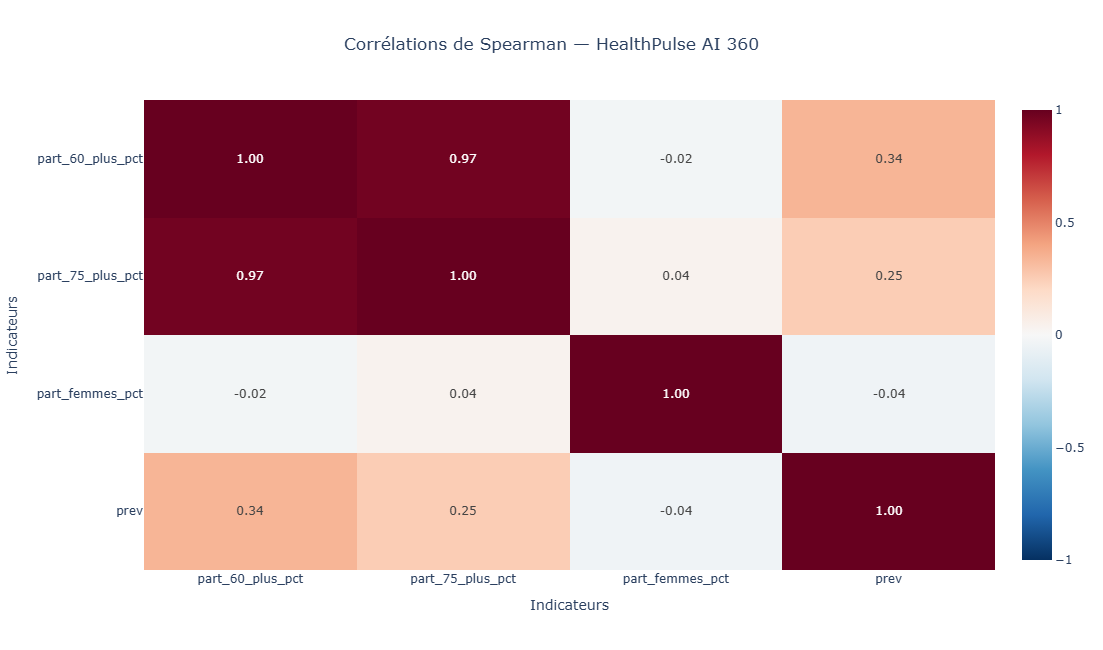

In [20]:
#Construire la heatmap

fig_heatmap = px.imshow(
    matrice_corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    aspect="auto",
    title="Corrélations de Spearman — HealthPulse AI 360",
    template="plotly_white"
)

fig_heatmap.update_layout(
    height=650,
    title_x=0.5,
    xaxis_title="Indicateurs",
    yaxis_title="Indicateurs"
)

fig_heatmap.show()

## 7. Analyse de sensibilité : Guyane et Mayotte

In [21]:
df_complet = df_analyse.copy()

In [22]:
#Construire un sous-ensemble de comparaison

df_sans_atypiques = df_analyse[
    ~df_analyse["code_dept"].isin(["973", "976"])
].copy()

print("Avec tous les territoires :", len(df_complet))

print("Sans Guyane et Mayotte :", len(df_sans_atypiques))

Avec tous les territoires : 101
Sans Guyane et Mayotte : 99


In [23]:
#Calculer les corrélations dans les 2 situations

resultats = pd.DataFrame({
    "Perimetre": [
        "Tous les départements",
        "Sans Guyane et Mayotte"
    ],
    "Pearson": [
        df_complet["part_60_plus_pct"].corr(
            df_complet["prev"], method="pearson"
        ),
        df_sans_atypiques["part_60_plus_pct"].corr(
            df_sans_atypiques["prev"], method="pearson"
        )
    ],
    "Spearman": [
        df_complet["part_60_plus_pct"].corr(
            df_complet["prev"], method="spearman"
        ),
        df_sans_atypiques["part_60_plus_pct"].corr(
            df_sans_atypiques["prev"], method="spearman"
        )
    ]
})

display(resultats.round(3))

,Perimetre,Pearson,Spearman
0,Tous les départements,0.316,0.341
1,Sans Guyane et Mayotte,0.332,0.326


In [24]:
#Mesurer l'écart entre les coefficients

variation_pearson = (
    resultats.loc[1, "Pearson"]
    - resultats.loc[0, "Pearson"]
)

print("Écart de Pearson :", round(variation_pearson, 3))

Écart de Pearson : 0.016


## 8. Exporter les résultats

In [25]:
fig_scatter.write_html(
    FIGURES / "j07_scatter_diabete_vieillissement.html",
    include_plotlyjs=True
)

fig_heatmap.write_html(
    FIGURES / "j07_heatmap_correlations.html",
    include_plotlyjs=True
)

In [26]:
#Exporter la matrice de corrélation

matrice_corr.to_csv(
    TABLES / "j07_matrice_spearman.csv",
    encoding="utf-8-sig"
)

In [27]:
#Exporter l'analyse de sensibilité

resultats.to_csv(
    TABLES / "j07_sensibilite_territoires.csv",
    index=False,
    encoding="utf-8-sig"
)

In [28]:
#Vérifier les fichiers crées

fichiers_sortie = [
    FIGURES / "j07_scatter_diabete_vieillissement.html",
    FIGURES / "j07_heatmap_correlations.html",
    TABLES / "j07_matrice_spearman.csv",
    TABLES / "j07_sensibilite_territoires.csv"
]

for f in fichiers_sortie:
    print(f.name, ":", f.exists())

j07_scatter_diabete_vieillissement.html : True
j07_heatmap_correlations.html : True
j07_matrice_spearman.csv : True
j07_sensibilite_territoires.csv : True
